In [1]:
import pandas as pd
import numpy as np
import networkx as nx

In [2]:
user_item_ratings_full = pd.read_csv('../data/processed_full/hotelrec_filtered_00001.csv')
user_item_ratings_full.drop_duplicates(subset=['user_id', 'item_id'], keep='first', inplace=True)
user_item_ratings = user_item_ratings_full[['user_id', 'item_id', 'rating']]
user_item_ratings_full

,user_id,item_id,rating,text,sleep quality,value,rooms,service,cleanliness,location
0,23,2,4.0,We made a brief stop to visit the 12th century...,NaN,NaN,NaN,NaN,NaN,4.0
1,24,2,5.0,Recently spent 2 nights here and used it as a ...,5.0,NaN,5.0,5.0,NaN,NaN
2,25,2,5.0,We totally enjoyed our granary cozy room with ...,NaN,NaN,NaN,NaN,NaN,NaN
3,26,2,4.0,I must start from the fact that it is a real c...,NaN,4.0,NaN,4.0,4.0,NaN
4,28,2,4.0,"Great agriturismo, in a fabulous setting. Cast...",NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
7575416,1511156,365056,5.0,We spent three nights over Labor Day weekend a...,NaN,NaN,NaN,NaN,NaN,NaN
7575417,1662983,365056,4.0,I stayed here in August - at first i was put o...,NaN,4.0,5.0,5.0,5.0,3.0
7575418,743117,365056,3.0,I got a free night at this property with my Hi...,NaN,3.0,3.0,5.0,3.0,4.0
7575420,272435,365056,3.0,"I stayed here for two nights, February 21-23, ...",NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# --- Initial Analysis ---
n_users = user_item_ratings['user_id'].nunique()
n_items = user_item_ratings['item_id'].nunique()
n_ratings = len(user_item_ratings)
sparsity = 1.0 - (n_ratings / (n_users * n_items))

print("--- Initial Dataset Analysis ---")
print(f"Number of unique users: {n_users}")
print(f"Number of unique items: {n_items}")
print(f"Number of ratings: {n_ratings}")
print(f"Sparsity of the user-item matrix: {sparsity:.4f}")
print("------------------------------------")

--- Initial Dataset Analysis ---
Number of unique users: 211273
Number of unique items: 249437
Number of ratings: 6098125
Sparsity of the user-item matrix: 0.9999
------------------------------------


In [4]:
# --- 2. Robust Bipartite Graph Construction ---
print("--- Step 2: Building a Robust Bipartite Graph (with Prefixes) ---\n")

B_robust = nx.Graph()

# Add user nodes with a 'u_' prefix
user_nodes = ['u_' + str(uid) for uid in user_item_ratings['user_id'].unique()]
B_robust.add_nodes_from(user_nodes, bipartite=0)

# Add item nodes with an 'i_' prefix
item_nodes = ['i_' + str(iid) for iid in user_item_ratings['item_id'].unique()]
B_robust.add_nodes_from(item_nodes, bipartite=1)

# Add edges with corresponding prefixes
edges = [('u_' + str(row['user_id']), 'i_' + str(row['item_id']))
         for idx, row in user_item_ratings.iterrows()]
B_robust.add_edges_from(edges)

print("Graph Construction Complete:")
print(f"  - Total nodes in graph: {B_robust.number_of_nodes()}")
print(f"  - Total edges (ratings) in graph: {B_robust.number_of_edges()}")
print("  - Self-loops are prevented by the prefixing strategy.\n")

--- Step 2: Building a Robust Bipartite Graph (with Prefixes) ---

Graph Construction Complete:
  - Total nodes in graph: 921420
  - Total edges (ratings) in graph: 6098125
  - Self-loops are prevented by the prefixing strategy.



In [5]:
# --- 3. K-Core Decomposition ---
# We are looking for a subgraph where every user has rated at least K items
# and every item has been rated by at least K users.
# This is a good value to experiment with for your specific dataset.
K_VALUE = 20 

print(f"--- Step 3: Performing K-Core Decomposition (k={K_VALUE}) ---\n")

core_subgraph = nx.k_core(B_robust, k=K_VALUE)

print("K-Core Subgraph Stats:")
print(f"  - Number of nodes in {K_VALUE}-core: {core_subgraph.number_of_nodes()}")
print(f"  - Number of edges (ratings) in {K_VALUE}-core: {core_subgraph.number_of_edges()}\n")

--- Step 3: Performing K-Core Decomposition (k=20) ---

K-Core Subgraph Stats:
  - Number of nodes in 20-core: 73857
  - Number of edges (ratings) in 20-core: 1400102



In [6]:
# --- 4. Filtering the DataFrame ---
print("--- Step 4: Filtering Original DataFrame to Create Dense Subset ---\n")

# Identify users/items by prefix instead of bipartite attribute
core_users_with_prefix = {n for n in core_subgraph.nodes() if n.startswith("u_")}
core_items_with_prefix = {n for n in core_subgraph.nodes() if n.startswith("i_")}

# Strip prefixes
core_users = {int(u[2:].split('.')[0]) for u in core_users_with_prefix}
core_items = {int(i[2:].split('.')[0]) for i in core_items_with_prefix}

# Use the cleaned sets of IDs to filter the original DataFrame
dense_ratings = user_item_ratings[
    user_item_ratings['user_id'].isin(core_users) &
    user_item_ratings['item_id'].isin(core_items)
].copy() # .copy() is good practice to avoid SettingWithCopyWarning

print("DataFrame filtering complete.\n")


--- Step 4: Filtering Original DataFrame to Create Dense Subset ---

DataFrame filtering complete.



In [7]:
# --- 5. Final Comparative Analysis ---
print("--- Step 5: Final Analysis - Original vs. Dense Core ---\n")

# Final Analysis on the dense subset
n_users_final = dense_ratings['user_id'].nunique()
n_items_final = dense_ratings['item_id'].nunique()
n_ratings_final = len(dense_ratings)
sparsity_final = 1.0 - (n_ratings_final / (n_users_final * n_items_final)) if (n_users_final * n_items_final) > 0 else 0
avg_ratings_orig = n_ratings / n_users
avg_ratings_final = n_ratings_final / n_users_final if n_users_final > 0 else 0

# Print a formatted comparison table
print("=" * 85)
print(f"{'Metric':<25} | {'Original Dataset':<25} | {'Dense Core (k=20)':<25}")
print("-" * 85)
print(f"{'Number of Users':<25} | {n_users:<25} | {n_users_final:<25}")
print(f"{'Number of Items':<25} | {n_items:<25} | {n_items_final:<25}")
print(f"{'Number of Ratings':<25} | {n_ratings:<25} | {n_ratings_final:<25}")
print("-" * 85)
print(f"{'Sparsity':<25} | {f'{sparsity:.6f}':<25} | {f'{sparsity_final:.6f}':<25}")
print(f"{'Avg. Ratings per User':<25} | {f'{avg_ratings_orig:.2f}':<25} | {f'{avg_ratings_final:.2f}':<25}")
print("=" * 85)

--- Step 5: Final Analysis - Original vs. Dense Core ---

Metric                    | Original Dataset          | Dense Core (k=20)        
-------------------------------------------------------------------------------------
Number of Users           | 211273                    | 46660                    
Number of Items           | 249437                    | 27197                    
Number of Ratings         | 6098125                   | 1400102                  
-------------------------------------------------------------------------------------
Sparsity                  | 0.999884                  | 0.998897                 
Avg. Ratings per User     | 28.86                     | 30.01                    


In [8]:
dense_ratings, user_item_ratings_full
# The dense_ratings DataFrame contains the filtered dense subset
# The user_item_ratings_full DataFrame contains the original full dataset with 6 additional columns
# transfere the additional columns to dense_ratings based on user_id and item_id
dense_ratings_full = dense_ratings.merge(
    user_item_ratings_full[['user_id', 'item_id', 'sleep quality', 'value', 'rooms', 'service', 'cleanliness','location', 'text']],
    on=['user_id', 'item_id'],
    how='left'
)
dense_ratings_full

,user_id,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,text
0,1521,19,5.0,NaN,5.0,NaN,5.0,5.0,NaN,The Courtyard Basel is in rarefied territory w...
1,1524,19,5.0,NaN,NaN,5.0,5.0,NaN,3.0,Have stayed here during a business trip. Very ...
2,1527,19,5.0,NaN,NaN,NaN,NaN,NaN,NaN,This hotel is far superior to the standard Cou...
3,1529,19,4.0,NaN,NaN,NaN,NaN,NaN,NaN,This was are first stay at this Marriott Court...
4,1530,19,4.0,NaN,NaN,NaN,NaN,NaN,NaN,This hotel is standard courtyard with clean ro...
...,...,...,...,...,...,...,...,...,...,...
1400097,613882,365056,5.0,NaN,4.0,5.0,NaN,5.0,5.0,I forgot to write a few reviews of our 07 summ...
1400098,1521429,365056,2.0,NaN,3.0,2.0,3.0,2.0,1.0,I booked this room via an opaque prepaid servi...
1400099,76310,365056,4.0,NaN,NaN,NaN,NaN,NaN,NaN,Got a great rate on priceline here (around $55...
1400100,272435,365056,3.0,NaN,NaN,NaN,NaN,NaN,NaN,"I stayed here for two nights, February 21-23, ..."


In [9]:
# save for Yann
dense_ratings_full.to_csv('hotelrec_dense_k20_Yann.csv', index=False)

# sentence former into PCA 100D Embedding

In [9]:
import pandas as pd
import numpy as np
import re
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA


/Users/maksiuuuuuuu/Library/Python/3.12/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
# --- Step 1: Clean the Text Column ---
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)  # Remove special characters
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra whitespace
    return text

# Apply cleaning to each entry in the 'text' column
dense_ratings_full['cleaned_text'] = dense_ratings_full['text'].apply(clean_text)

# drop the text column
dense_ratings_full.drop(columns=['text'], inplace=True)

In [11]:
# --- Step 2: Generate Initial Embeddings for Each Text Entry ---
print("Loading sentence-transformer model...")
model = SentenceTransformer('all-MiniLM-L6-v2')

print("Generating initial 384-dimensional embeddings for each text entry...")
# Ensure we handle any potentially empty text fields after cleaning
texts_to_embed = dense_ratings_full['cleaned_text'].tolist()
initial_embeddings = model.encode(texts_to_embed, show_progress_bar=True)

Loading sentence-transformer model...
Generating initial 384-dimensional embeddings for each text entry...


Batches: 100%|██████████| 43754/43754 [35:02<00:00, 20.81it/s]  


In [12]:
# --- Step 3: Reduce Dimensionality with PCA ---
N_DIMENSIONS = 100
print(f"\nReducing embeddings to {N_DIMENSIONS} dimensions using PCA...")
pca = PCA(n_components=N_DIMENSIONS)
reduced_embeddings = pca.fit_transform(initial_embeddings)

print(f"Shape of the final embeddings matrix: {reduced_embeddings.shape}")
print("\n")


Reducing embeddings to 100 dimensions using PCA...
Shape of the final embeddings matrix: (1400102, 100)




In [13]:
# --- Step 4: Format, Concatenate, and Clean Up ---
# Create column names for the new embedding features
feature_cols = [f'text_emb_{i}' for i in range(N_DIMENSIONS)]

# Create a new DataFrame with the reduced embeddings
# Use float32 for memory efficiency. Use float16 if you need even more memory savings
# and can tolerate a small loss in precision.
features_df = pd.DataFrame(reduced_embeddings, columns=feature_cols).astype('float32')

# Concatenate the new features with the original DataFrame
# We reset the index to ensure a clean join
dense_ratings_full.reset_index(drop=True, inplace=True)
features_df.reset_index(drop=True, inplace=True)
final_df = pd.concat([dense_ratings_full, features_df], axis=1)

# Drop the original and intermediate text columns
final_df.drop(columns=['cleaned_text'], inplace=True)

print("--- Final Processed DataFrame with 100-Dimension Embeddings ---")
print(final_df.head())
print(f"\nShape of the final DataFrame: {final_df.shape}")
print("Final columns:", final_df.columns.tolist()[:5], "...", final_df.columns.tolist()[-5:])
print(f"Memory usage of final DataFrame: {final_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

--- Final Processed DataFrame with 100-Dimension Embeddings ---
   user_id  item_id  rating  sleep quality  value  rooms  service  \
0     1521       19     5.0            NaN    5.0    NaN      5.0   
1     1524       19     5.0            NaN    NaN    5.0      5.0   
2     1527       19     5.0            NaN    NaN    NaN      NaN   
3     1529       19     4.0            NaN    NaN    NaN      NaN   
4     1530       19     4.0            NaN    NaN    NaN      NaN   

   cleanliness  location  text_emb_0  ...  text_emb_90  text_emb_91  \
0          5.0       NaN   -0.041622  ...     0.051783     0.090821   
1          NaN       3.0    0.094268  ...     0.007869    -0.021458   
2          NaN       NaN    0.226007  ...     0.035656     0.022072   
3          NaN       NaN    0.026531  ...     0.003374     0.041171   
4          NaN       NaN    0.133377  ...    -0.012842    -0.004858   

   text_emb_92  text_emb_93  text_emb_94  text_emb_95  text_emb_96  \
0     0.023550    -0.028

In [15]:
# save the embedded dataset:
final_df.to_csv('../data/processed_full/hotelrec_dense_k20_embedded_SBERT_PCA.csv', index=False)

# Statistical Data

In [16]:
# create user and item feature showing correlation between rating and any subrating based on ratings_full
# Then append to user_df or item_df

# Per user correlation between rating and subratings
user_correlations = []
for user_id, group in dense_ratings_full.groupby('user_id'):
    user_corr = {'user_id': user_id}
    for subrating in ['sleep quality', 'value', 'rooms', 'service', 'cleanliness', 'location']:
        if group[subrating].nunique() > 1:  # Ensure there is variance
            corr = group['rating'].corr(group[subrating])
            user_corr[f'corr_rating_{subrating}'] = corr
        else:
            user_corr[f'corr_rating_{subrating}'] = np.nan
    user_correlations.append(user_corr)
user_corr_df = pd.DataFrame(user_correlations)

# Per item correlation between rating and subratings
item_correlations = []
for item_id, group in dense_ratings_full.groupby('item_id'):
    item_corr = {'item_id': item_id}
    for subrating in ['sleep quality', 'value', 'rooms', 'service', 'cleanliness', 'location']:
        if group[subrating].nunique() > 1:  # Ensure there is variance
            corr = group['rating'].corr(group[subrating])
            item_corr[f'corr_rating_{subrating}'] = corr
        else:
            item_corr[f'corr_rating_{subrating}'] = np.nan
    item_correlations.append(item_corr)
item_corr_df = pd.DataFrame(item_correlations)

item_corr_df

/Users/maksiuuuuuuu/Library/Python/3.12/lib/python/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/maksiuuuuuuu/Library/Python/3.12/lib/python/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,item_id,corr_rating_sleep quality,corr_rating_value,corr_rating_rooms,corr_rating_service,corr_rating_cleanliness,corr_rating_location
0,19,0.671665,0.565819,0.399244,0.782182,0.698705,0.495598
1,22,0.831531,0.562367,0.681994,0.683204,0.718952,0.402618
2,23,0.753385,0.758507,0.766528,0.609087,0.672874,0.624330
3,37,0.460283,0.644462,0.840498,0.727607,0.292603,0.679366
4,43,0.288675,0.658586,0.686406,0.413070,0.588172,0.648074
...,...,...,...,...,...,...,...
27192,365046,0.597250,0.607186,0.782483,0.674200,0.612691,0.206534
27193,365053,0.761108,0.646587,0.643350,0.701963,0.675739,0.368008
27194,365054,0.273288,0.746407,0.633630,0.472496,0.403291,0.157334
27195,365055,-0.475191,0.685994,0.550000,0.609721,0.580948,0.509175


In [17]:
# Lets analyze the users and items and create a user_df and item_df with their average subratings
user_df = dense_ratings_full.groupby('user_id').agg({
    'rating': 'mean',
    'sleep quality': 'mean',
    'value': 'mean',
    'rooms': 'mean',
    'service': 'mean',
    'cleanliness': 'mean',
    'location': 'mean',
    'item_id': 'count'
}).reset_index().rename(columns={'item_id': 'num_rated_items'})

item_df = dense_ratings_full.groupby('item_id').agg({
    'rating': 'mean',
    'sleep quality': 'mean',
    'value': 'mean',
    'rooms': 'mean',
    'service': 'mean',
    'cleanliness': 'mean',
    'location': 'mean',
    'user_id': 'count'
}).reset_index().rename(columns={'user_id': 'num_ratings'})

# Save the dataframes to CSV files


user_df

,user_id,rating,sleep quality,value,rooms,service,cleanliness,location,num_rated_items
0,8,4.968750,5.000000,5.000000,5.000000,4.967742,5.000000,4.916667,32
1,12,4.187500,4.000000,4.277778,4.250000,4.612903,4.900000,4.722222,32
2,23,3.925926,3.866667,3.888889,3.750000,4.076923,4.230769,4.642857,27
3,25,4.166667,4.250000,4.153846,4.285714,4.185185,4.277778,4.357143,42
4,26,3.761905,3.928571,3.611111,3.909091,3.380952,3.687500,4.076923,21
...,...,...,...,...,...,...,...,...,...
46655,9220075,3.700000,4.000000,4.062500,3.600000,3.789474,4.166667,3.687500,20
46656,9420670,4.000000,4.272727,4.000000,3.937500,4.263158,4.500000,4.700000,21
46657,9650246,3.739130,4.583333,4.000000,4.000000,4.142857,4.769231,4.583333,23
46658,10116296,4.550000,5.000000,4.571429,3.750000,4.571429,4.700000,5.000000,20


In [18]:
# Concat the correlation features to user_df and item_df
user_df = user_df.merge(user_corr_df, on='user_id', how='left')
item_df = item_df.merge(item_corr_df, on='item_id', how='left')
user_df

,user_id,rating,sleep quality,value,rooms,service,cleanliness,location,num_rated_items,corr_rating_sleep quality,corr_rating_value,corr_rating_rooms,corr_rating_service,corr_rating_cleanliness,corr_rating_location
0,8,4.968750,5.000000,5.000000,5.000000,4.967742,5.000000,4.916667,32,NaN,NaN,NaN,-0.033333,NaN,1.000000
1,12,4.187500,4.000000,4.277778,4.250000,4.612903,4.900000,4.722222,32,0.824589,0.721186,0.577350,0.671725,0.390109,0.538028
2,23,3.925926,3.866667,3.888889,3.750000,4.076923,4.230769,4.642857,27,0.837389,0.951176,0.949168,0.838224,0.866706,0.825765
3,25,4.166667,4.250000,4.153846,4.285714,4.185185,4.277778,4.357143,42,0.382971,0.717496,0.683177,0.718194,0.450217,0.715133
4,26,3.761905,3.928571,3.611111,3.909091,3.380952,3.687500,4.076923,21,0.836425,0.602876,0.451335,0.815365,0.788914,0.205196
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46655,9220075,3.700000,4.000000,4.062500,3.600000,3.789474,4.166667,3.687500,20,0.735057,0.688050,0.859018,0.867354,0.716222,0.752281
46656,9420670,4.000000,4.272727,4.000000,3.937500,4.263158,4.500000,4.700000,21,0.417311,0.571040,0.766292,0.766545,0.000000,0.312348
46657,9650246,3.739130,4.583333,4.000000,4.000000,4.142857,4.769231,4.583333,23,0.727496,0.818466,0.833205,0.883883,0.754182,0.390567
46658,10116296,4.550000,5.000000,4.571429,3.750000,4.571429,4.700000,5.000000,20,NaN,0.113228,0.817303,0.832424,0.937043,NaN


In [21]:
# Also include the average embedding per user and item
# Get the list of your new embedding columns
embedding_cols = [f'text_emb_{i}' for i in range(N_DIMENSIONS)]

# --- Create Item Features ---
# The average embedding of all reviews for an item
item_features = final_df.groupby('item_id')[embedding_cols].mean()
print("\n--- Aggregated Item Features (Example) ---")

# --- Create User Features ---
# The average embedding of all reviews written by a user
user_features = final_df.groupby('user_id')[embedding_cols].mean()
print("\n--- Aggregated User Features (Example) ---")

user_features


--- Aggregated Item Features (Example) ---

--- Aggregated User Features (Example) ---


,text_emb_0,text_emb_1,text_emb_2,text_emb_3,text_emb_4,text_emb_5,text_emb_6,text_emb_7,text_emb_8,text_emb_9,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
user_id,,,,,,,,,,,,,,,,,,,,,
8,0.066042,0.080365,0.114212,-0.076297,-0.035579,-0.097351,-0.072490,-0.047464,-0.031106,0.005100,...,-0.013878,-0.002051,0.011432,-0.004151,-0.002034,-0.019433,-0.007476,-0.004459,0.003242,0.004993
12,-0.032159,-0.106139,-0.017192,-0.004058,-0.028654,0.041117,-0.019490,-0.019980,-0.023885,0.032127,...,0.007225,-0.004761,0.006946,-0.000852,0.008241,0.000151,0.007699,-0.003459,-0.002650,-0.017329
23,-0.108345,0.086133,-0.007928,-0.000037,-0.050367,0.017634,-0.091477,-0.001089,0.052799,0.073587,...,-0.008082,0.004488,-0.004359,-0.002172,0.020979,-0.011370,0.005325,-0.004700,-0.013979,-0.003620
25,0.079490,0.043476,-0.085493,-0.000343,-0.024844,-0.060723,0.048953,-0.032579,-0.023844,0.031156,...,-0.008281,0.003502,-0.011688,0.002253,0.002044,0.008348,-0.003149,-0.004344,0.007763,0.009010
26,-0.053362,-0.130048,0.114312,0.058831,0.061576,-0.067228,0.037861,-0.094756,0.064597,0.058208,...,-0.012055,-0.020730,-0.008691,-0.009486,-0.015362,0.009323,-0.010816,0.002655,-0.000484,-0.002226
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9220075,-0.122843,-0.091806,0.063609,0.053672,-0.032927,-0.022817,0.046615,0.036015,0.024568,-0.018101,...,0.010957,0.003665,0.014411,-0.003123,0.021362,-0.022861,-0.006422,0.029437,-0.013981,-0.004602
9420670,-0.067721,0.118499,0.054821,0.025454,-0.053124,0.085283,-0.025081,0.030546,0.038247,0.078973,...,0.014086,-0.009993,0.013033,0.009649,-0.005281,0.008853,-0.010388,-0.004512,0.006875,0.017469
9650246,-0.094879,-0.033366,0.013500,0.079422,-0.008016,-0.084611,0.071183,0.004955,0.002879,-0.000410,...,-0.003595,-0.005995,-0.011916,-0.011783,-0.007285,0.004958,-0.016646,0.010111,0.010220,-0.010841


In [22]:
# Concat the embedding features to user_df and item_df
user_df = user_df.merge(user_features, on='user_id', how='left')
item_df = item_df.merge(item_features, on='item_id', how='left')
user_df


,user_id,rating,sleep quality,value,rooms,service,cleanliness,location,num_rated_items,corr_rating_sleep quality,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,8,4.968750,5.000000,5.000000,5.000000,4.967742,5.000000,4.916667,32,NaN,...,-0.013878,-0.002051,0.011432,-0.004151,-0.002034,-0.019433,-0.007476,-0.004459,0.003242,0.004993
1,12,4.187500,4.000000,4.277778,4.250000,4.612903,4.900000,4.722222,32,0.824589,...,0.007225,-0.004761,0.006946,-0.000852,0.008241,0.000151,0.007699,-0.003459,-0.002650,-0.017329
2,23,3.925926,3.866667,3.888889,3.750000,4.076923,4.230769,4.642857,27,0.837389,...,-0.008082,0.004488,-0.004359,-0.002172,0.020979,-0.011370,0.005325,-0.004700,-0.013979,-0.003620
3,25,4.166667,4.250000,4.153846,4.285714,4.185185,4.277778,4.357143,42,0.382971,...,-0.008281,0.003502,-0.011688,0.002253,0.002044,0.008348,-0.003149,-0.004344,0.007763,0.009010
4,26,3.761905,3.928571,3.611111,3.909091,3.380952,3.687500,4.076923,21,0.836425,...,-0.012055,-0.020730,-0.008691,-0.009486,-0.015362,0.009323,-0.010816,0.002655,-0.000484,-0.002226
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46655,9220075,3.700000,4.000000,4.062500,3.600000,3.789474,4.166667,3.687500,20,0.735057,...,0.010957,0.003665,0.014411,-0.003123,0.021362,-0.022861,-0.006422,0.029437,-0.013981,-0.004602
46656,9420670,4.000000,4.272727,4.000000,3.937500,4.263158,4.500000,4.700000,21,0.417311,...,0.014086,-0.009993,0.013033,0.009649,-0.005281,0.008853,-0.010388,-0.004512,0.006875,0.017469
46657,9650246,3.739130,4.583333,4.000000,4.000000,4.142857,4.769231,4.583333,23,0.727496,...,-0.003595,-0.005995,-0.011916,-0.011783,-0.007285,0.004958,-0.016646,0.010111,0.010220,-0.010841
46658,10116296,4.550000,5.000000,4.571429,3.750000,4.571429,4.700000,5.000000,20,NaN,...,0.019979,0.012035,0.016988,0.012199,0.015253,-0.001930,0.000959,-0.014450,0.003064,-0.015476


In [24]:
# Normalize user_df, item_df and final_df - devide all rating columns by 5.0 (rating	sleep quality	value	rooms	service	cleanliness	location)
# num_rated_items by max value
rating_columns = ['rating', 'sleep quality', 'value', 'rooms', 'service', 'cleanliness', 'location']
for col in rating_columns:
    user_df[col] = user_df[col] / 5.0
    item_df[col] = item_df[col] / 5.0
    final_df[col] = final_df[col] / 5.0
    
max_num_rated_items = user_df['num_rated_items'].max()
user_df['num_rated_items'] = user_df['num_rated_items'] / max_num_rated_items

max_num_ratings = item_df['num_ratings'].max()
item_df['num_ratings'] = item_df['num_ratings'] / max_num_ratings

In [31]:
# Save the dense subset to a new CSV file
final_df.to_csv('../data/processed_full/user_item_processed_data.csv', index=False)
user_df.to_csv('../data/processed_full/user_features.csv', index=False)
item_df.to_csv('../data/processed_full/item_features.csv', index=False)

# Analyze Data

In [27]:
# Analyze these dataframes Lets calculate correlations between subratings and overall rating for each subrating for each user and measure their overall importance
subrating_cols = ['sleep quality', 'value', 'rooms', 'service', 'cleanliness', 'location']
correlations = {}
for col in subrating_cols:
    correlation = dense_ratings_full['rating'].corr(dense_ratings_full[col])
    correlations[col] = correlation
correlations_df = pd.DataFrame.from_dict(correlations, orient='index', columns=['correlation_with_overall_rating'])
correlations_df = correlations_df.sort_values(by='correlation_with_overall_rating', ascending=False)
correlations_df

,correlation_with_overall_rating
rooms,0.763721
service,0.717042
value,0.713863
cleanliness,0.682953
sleep quality,0.682564
location,0.477202


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

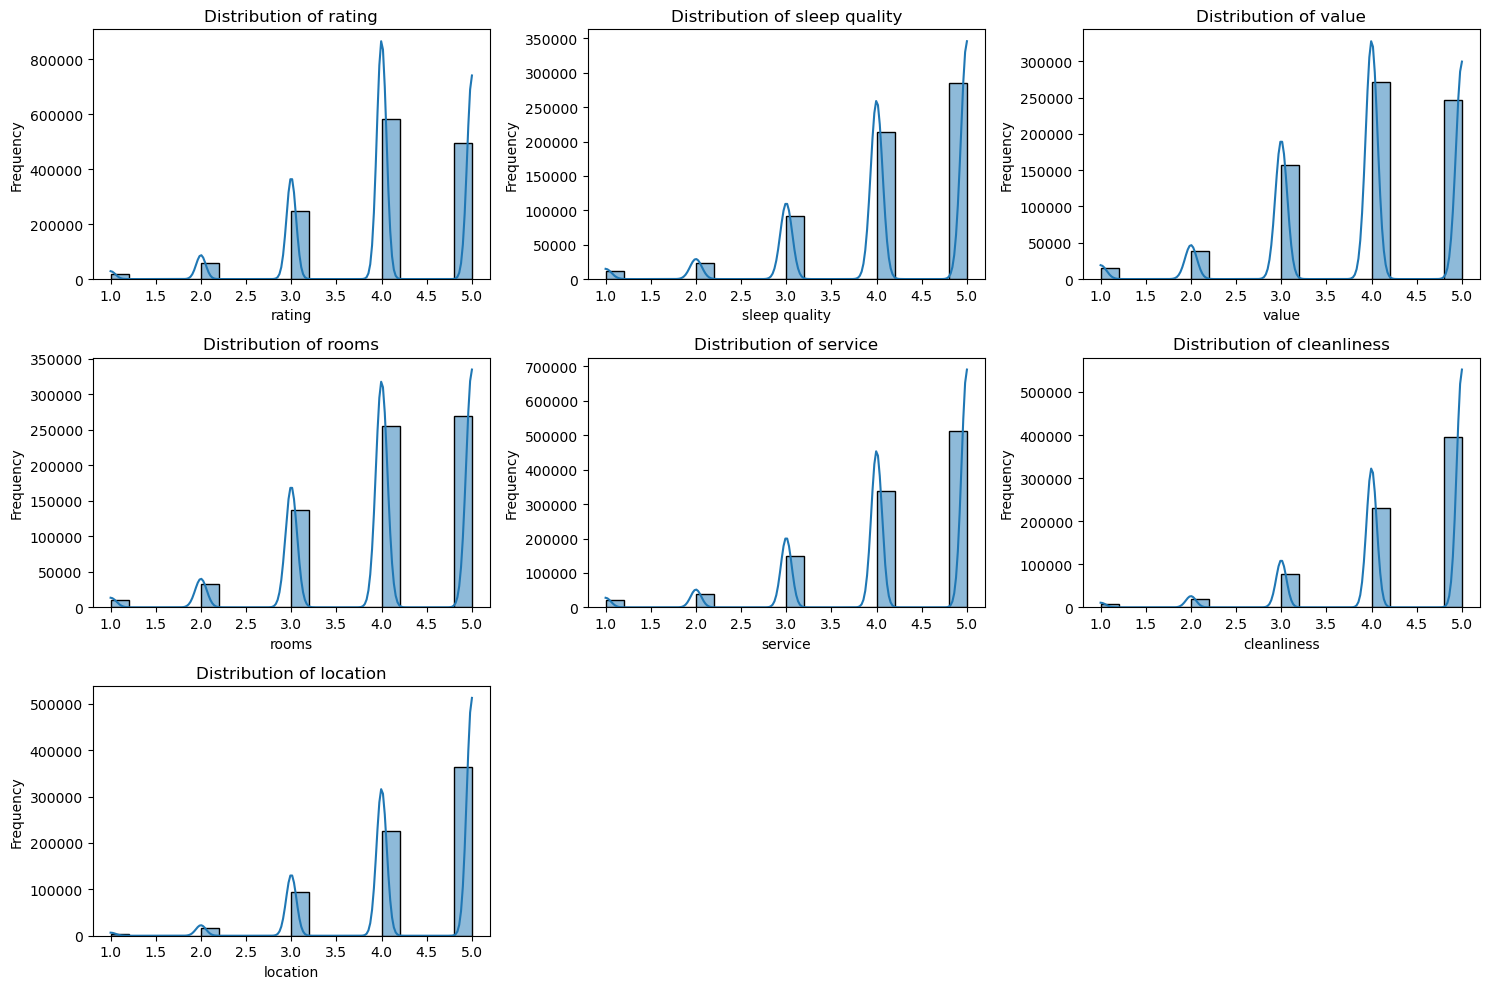

In [21]:
# Lets now analyze and plot distributions of general ratings and subratings in dense_ratings_full
import matplotlib.pyplot as plt
import seaborn as sns
# Set up the matplotlib figure
plt.figure(figsize=(15, 10))
# List of columns to plot
columns_to_plot = ['rating', 'sleep quality', 'value', 'rooms', 'service', 'cleanliness', 'location']
# Plot each column
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(3, 3, i)
    sns.histplot(dense_ratings_full[column], bins=20, kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


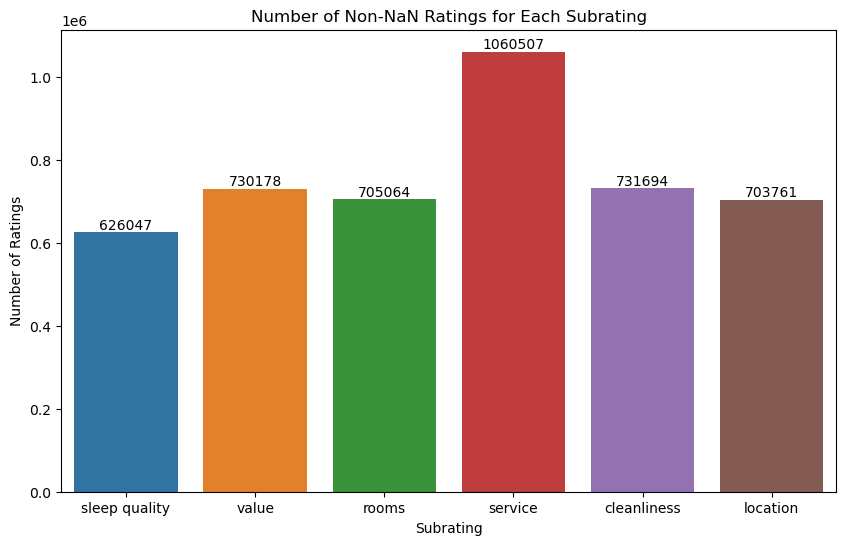

In [24]:
# now graph now many non nan ratings do we have for each subrating - show values as a bar plot
plt.figure(figsize=(10, 6))
subrating_counts = {
    'sleep quality': dense_ratings_full['sleep quality'].notna().sum(),
    'value': dense_ratings_full['value'].notna().sum(),
    'rooms': dense_ratings_full['rooms'].notna().sum(),
    'service': dense_ratings_full['service'].notna().sum(),
    'cleanliness': dense_ratings_full['cleanliness'].notna().sum(),
    'location': dense_ratings_full['location'].notna().sum()
}
sns.barplot(x=list(subrating_counts.keys()), y=list(subrating_counts.values()))
# Add values to the bar plot
for i, v in enumerate(subrating_counts.values()):
    plt.text(i, v + 50, str(v), ha='center', va='bottom')
plt.title('Number of Non-NaN Ratings for Each Subrating')
plt.xlabel('Subrating')
plt.ylabel('Number of Ratings')
plt.show()